# GoogLeNet Transfer Learning on Flowers-102

Compare feature extraction and full fine-tuning of ImageNet-pretrained GoogLeNet for 102 flower categories. This completed experiment uses the official training and validation partitions, auxiliary training losses, and the best validation checkpoint for each strategy.

Completed as part of my Deep Learning coursework. The reported results are validation results: the official test split was not evaluated in this experiment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Inception architecture

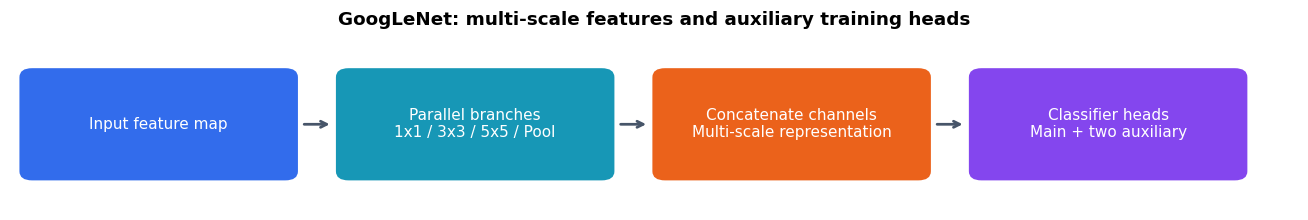

In [2]:
show_architecture(['Input feature map','Parallel branches\n1x1 / 3x3 / 5x5 / Pool','Concatenate channels\nMulti-scale representation','Classifier heads\nMain + two auxiliary'], 'GoogLeNet: multi-scale features and auxiliary training heads')

In [3]:
import os
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms, datasets
from torchvision.models import googlenet, GoogLeNet_Weights

from sklearn.metrics import confusion_matrix, classification_report

torch.set_num_threads(2)
assert torch.cuda.is_available(), 'A GPU is required for this training run.'
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

Using device: cuda


## Data preparation and image normalization

GoogLeNet requires input tensors of shape `(N, 3, 224, 224)` normalized with ImageNet mean ($\mu$) and standard deviation ($\sigma$) vectors:
- **Mean:** $[0.485, 0.456, 0.406]$
- **Std:** $[0.229, 0.224, 0.225]$

We load the `Flowers102` dataset and construct PyTorch `DataLoader` objects with a batch size of 32.

In [4]:
# Build the torchvision layout from attached images and verified benchmark metadata.
from pathlib import Path
import shutil, hashlib
base = Path('/tmp/coursework-data/flowers-102')
base.mkdir(parents=True, exist_ok=True)
image_matches = list(Path('/kaggle/input').rglob('image_00001.jpg'))
if len(image_matches) != 1:
    raise RuntimeError(f'Expected one Flowers102 image collection; found {len(image_matches)}')
images = image_matches[0].parent
if len(list(images.glob('image_*.jpg'))) != 8189:
    raise RuntimeError('The Flowers102 image collection is incomplete.')
if not (base/'jpg').exists():
    (base/'jpg').symlink_to(images, target_is_directory=True)
checksums = {'imagelabels.mat':'e0620be6f572b9609742df49c70aed4d',
             'setid.mat':'a5357ecc9cb78c4bef273ce3793fc85c'}
for filename, checksum in checksums.items():
    matches = [p for p in Path('/kaggle/input').rglob(filename)
               if hashlib.md5(p.read_bytes()).hexdigest() == checksum]
    if not matches:
        raise RuntimeError(f'Missing verified Flowers102 metadata: {filename}')
    shutil.copy2(matches[0], base/filename)
weights = next(Path('/kaggle/input').rglob('googlenet-1378be20.pth'))
if not hashlib.sha256(weights.read_bytes()).hexdigest().startswith('1378be20'):
    raise RuntimeError('Pretrained weight checksum mismatch.')
weight_cache = Path(torch.hub.get_dir())/'checkpoints'
weight_cache.mkdir(parents=True, exist_ok=True)
shutil.copy2(weights, weight_cache/weights.name)

# Task 1a: Define image transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ]),
    'val': transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ]),
}

# Download and instantiate Flowers102 dataset
data_dir = '/tmp/coursework-data'

train_dataset = datasets.Flowers102(
    root=data_dir, split='train', download=False, transform=data_transforms['train']
)
val_dataset = datasets.Flowers102(
    root=data_dir, split='val', download=False, transform=data_transforms['val']
)

# Task 1b: Instantiate DataLoader objects (batch size = 32)
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Infer number of target classes
num_classes = 102  # Flowers102 default class count
print(f"Train Dataset Size: {len(train_dataset)}")
print(f"Validation Dataset Size: {len(val_dataset)}")
print(f"Number of target classes (C): {num_classes}")

Train Dataset Size: 1020
Validation Dataset Size: 1020
Number of target classes (C): 102


### Flower examples

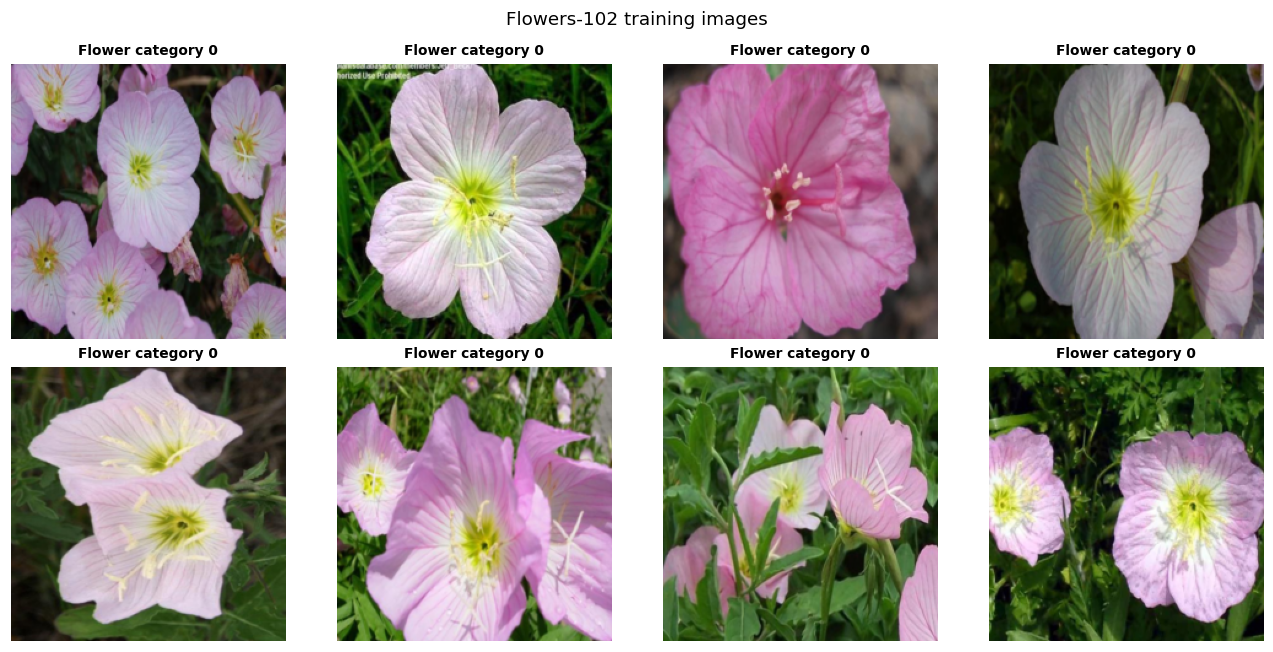

In [5]:
mean=np.array([.485,.456,.406]); std=np.array([.229,.224,.225])
fig,axes=plt.subplots(2,4,figsize=(12,6))
for i,ax in enumerate(axes.flat):
    image,label=train_dataset[i]
    image=image.permute(1,2,0).numpy()*std+mean
    ax.imshow(np.clip(image,0,1)); ax.set_title(f'Flower category {label}',fontsize=9); ax.axis('off')
fig.suptitle('Flowers-102 training images'); plt.tight_layout(); plt.show()

## Adapting GoogLeNet to flower categories

1. **Load Pre-trained Model:** Initialize `googlenet` with `GoogLeNet_Weights.DEFAULT` and `aux_logits=True`.
2. **Modify FC Layers:**
   - Replace main classifier (`model.fc`).
   - Replace auxiliary classifiers (`model.aux1.fc2` and `model.aux2.fc2`).
3. **Freeze/Unfreeze Parameters:**
   - **Feature Extraction:** Freeze backbone weights, keep `fc`, `aux1.fc2`, and `aux2.fc2` trainable.
   - **Fine-Tuning:** Keep all model parameters trainable.

In [6]:
def get_googlenet_model(num_classes, feature_extract=True):
    # Task 2a: Load pre-trained GoogLeNet weights
    model = googlenet(weights=GoogLeNet_Weights.DEFAULT, aux_logits=True)

    # Task 3a: Feature Extraction - Freeze all parameters initially
    if feature_extract:
        for param in model.parameters():
            param.requires_grad = False

    # Task 2b: Replace final classification layer
    in_features_main = model.fc.in_features
    model.fc = nn.Linear(in_features_main, num_classes)

    # Task 2c: Replace auxiliary classification layers (named fc2 in torchvision)
    in_features_aux1 = model.aux1.fc2.in_features
    model.aux1.fc2 = nn.Linear(in_features_aux1, num_classes)

    in_features_aux2 = model.aux2.fc2.in_features
    model.aux2.fc2 = nn.Linear(in_features_aux2, num_classes)

    # Ensure newly replaced layers are trainable
    if feature_extract:
        for param in model.fc.parameters():
            param.requires_grad = True
        for param in model.aux1.fc2.parameters():
            param.requires_grad = True
        for param in model.aux2.fc2.parameters():
            param.requires_grad = True

    model.feature_extract = feature_extract
    return model

### Feature extraction versus fine-tuning

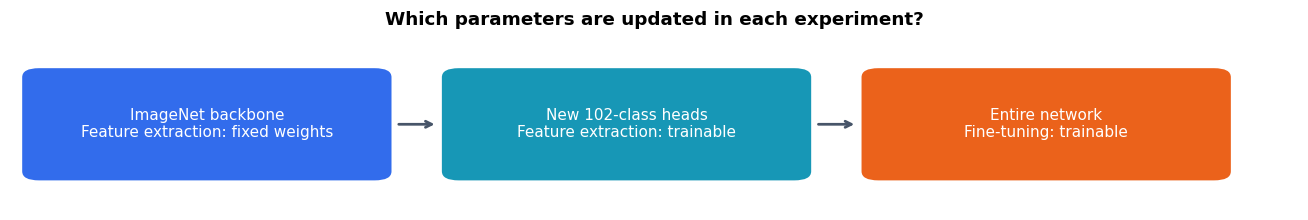

In [7]:
show_architecture(['ImageNet backbone\nFeature extraction: fixed weights','New 102-class heads\nFeature extraction: trainable','Entire network\nFine-tuning: trainable'], 'Which parameters are updated in each experiment?')

## Training with auxiliary classifiers

During training (`model.train()`), GoogLeNet returns outputs containing main logits and auxiliary logits:
$$\text{Total Loss} = \text{Loss}_{\text{main}} + 0.3 \times \text{Loss}_{\text{aux1}} + 0.3 \times \text{Loss}_{\text{aux2}}$$

During evaluation (`model.eval()`), GoogLeNet returns only main logits.

In [8]:
def train_googlenet_model(model, dataloaders, criterion, optimizer, num_epochs=10):
    since = time.time()

    history = {
        'train_loss': [],
        'train_total_loss': [],
        'val_loss': [],
        'val_acc': []
    }

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        print("-" * 30)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                if getattr(model, 'feature_extract', False):
                    for module in model.modules():
                        if isinstance(module, nn.modules.batchnorm._BatchNorm):
                            module.eval()
            else:
                model.eval()

            running_loss = 0.0
            running_main_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    if phase == 'train':
                        # Task 4a: Training mode returns namedtuple (logits, aux_logits2, aux_logits1)
                        outputs = model(inputs)
                        logits = outputs.logits
                        aux_logits2 = outputs.aux_logits2
                        aux_logits1 = outputs.aux_logits1

                        loss_main = criterion(logits, labels)
                        loss_aux2 = criterion(aux_logits2, labels)
                        loss_aux1 = criterion(aux_logits1, labels)

                        # Task 4: Total loss formulation with 0.3 weight factor
                        loss = loss_main + 0.3 * loss_aux1 + 0.3 * loss_aux2

                        loss.backward()
                        optimizer.step()
                    else:
                        # Task 4b: Eval mode returns main logits directly
                        logits = model(inputs)
                        loss = criterion(logits, labels)

                    _, preds = torch.max(logits, 1)

                running_loss += loss.item() * inputs.size(0)
                running_main_loss += (loss_main if phase == "train" else loss).item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = (running_corrects.double() / len(dataloaders[phase].dataset)).item()

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == 'train':
                history['train_loss'].append(running_main_loss / len(dataloaders[phase].dataset))
                history['train_total_loss'].append(epoch_loss)
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc)

                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Validation Accuracy: {best_acc:.4f}")

    model.load_state_dict(best_model_wts)
    return model, history

## Experiment A: Feature Extraction Strategy

In this experiment, the pre-trained weights of the GoogLeNet backbone are frozen. Only the classification heads (`fc`, `aux1.fc2`, and `aux2.fc2`) are trained using standard learning rate ($10^{-3}$).

In [9]:
torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)
print("=== Starting Experiment A: Feature Extraction ===")

# Instantiate feature extraction model
model_feature_extract = get_googlenet_model(num_classes=num_classes, feature_extract=True)
model_feature_extract = model_feature_extract.to(device)

# Filter parameters that require gradients
params_to_update_fe = [p for p in model_feature_extract.parameters() if p.requires_grad]

criterion = nn.CrossEntropyLoss()
optimizer_fe = optim.Adam(params_to_update_fe, lr=1e-3)

dataloaders = {'train': train_loader, 'val': val_loader}

# Train feature extraction model for 10 epochs
model_feature_extract, history_fe = train_googlenet_model(
    model_feature_extract,
    dataloaders,
    criterion,
    optimizer_fe,
    num_epochs=10
)

=== Starting Experiment A: Feature Extraction ===


/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


Epoch 1/10
------------------------------


Train Loss: 7.3445 Acc: 0.0618


Val Loss: 3.8466 Acc: 0.3922

Epoch 2/10
------------------------------


...

Val Loss: 1.4635 Acc: 0.7765

Epoch 9/10
------------------------------


Train Loss: 2.5976 Acc: 0.9657


Val Loss: 1.3735 Acc: 0.7853

Epoch 10/10
------------------------------


Train Loss: 2.4314 Acc: 0.9716


Val Loss: 1.2920 Acc: 0.7902

Training complete in 2m 48s
Best Validation Accuracy: 0.7902


## Experiment B: Fine-Tuning Strategy

In this experiment, all parameters across the entire GoogLeNet network are unfrozen and updated using a smaller learning rate ($10^{-4}$).

In [10]:
torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)
print("=== Starting Experiment B: Fine-Tuning ===")

# Instantiate fine-tuning model (unfrozen backbone)
model_fine_tune = get_googlenet_model(num_classes=num_classes, feature_extract=False)
model_fine_tune = model_fine_tune.to(device)

criterion = nn.CrossEntropyLoss()
# Task 3b: Fine-tuning with smaller learning rate (1e-4)
optimizer_ft = optim.Adam(model_fine_tune.parameters(), lr=1e-4)

# Train fine-tuning model for 10 epochs
model_fine_tune, history_ft = train_googlenet_model(
    model_fine_tune,
    dataloaders,
    criterion,
    optimizer_ft,
    num_epochs=10
)

=== Starting Experiment B: Fine-Tuning ===


Epoch 1/10
------------------------------


Train Loss: 7.4161 Acc: 0.0422


Val Loss: 4.2912 Acc: 0.1941

Epoch 2/10
------------------------------


Train Loss: 6.5701 Acc: 0.4578


...

Val Loss: 1.8226 Acc: 0.8324

Epoch 9/10
------------------------------


Train Loss: 1.9758 Acc: 0.9971


Val Loss: 1.6567 Acc: 0.8441

Epoch 10/10
------------------------------


Train Loss: 1.6016 Acc: 0.9980


Val Loss: 1.4979 Acc: 0.8490

Training complete in 3m 1s
Best Validation Accuracy: 0.8490


## Training and validation curves

Plots comparing Training Loss, Validation Loss, and Validation Accuracy across 10 epochs for Feature Extraction vs. Fine-Tuning.

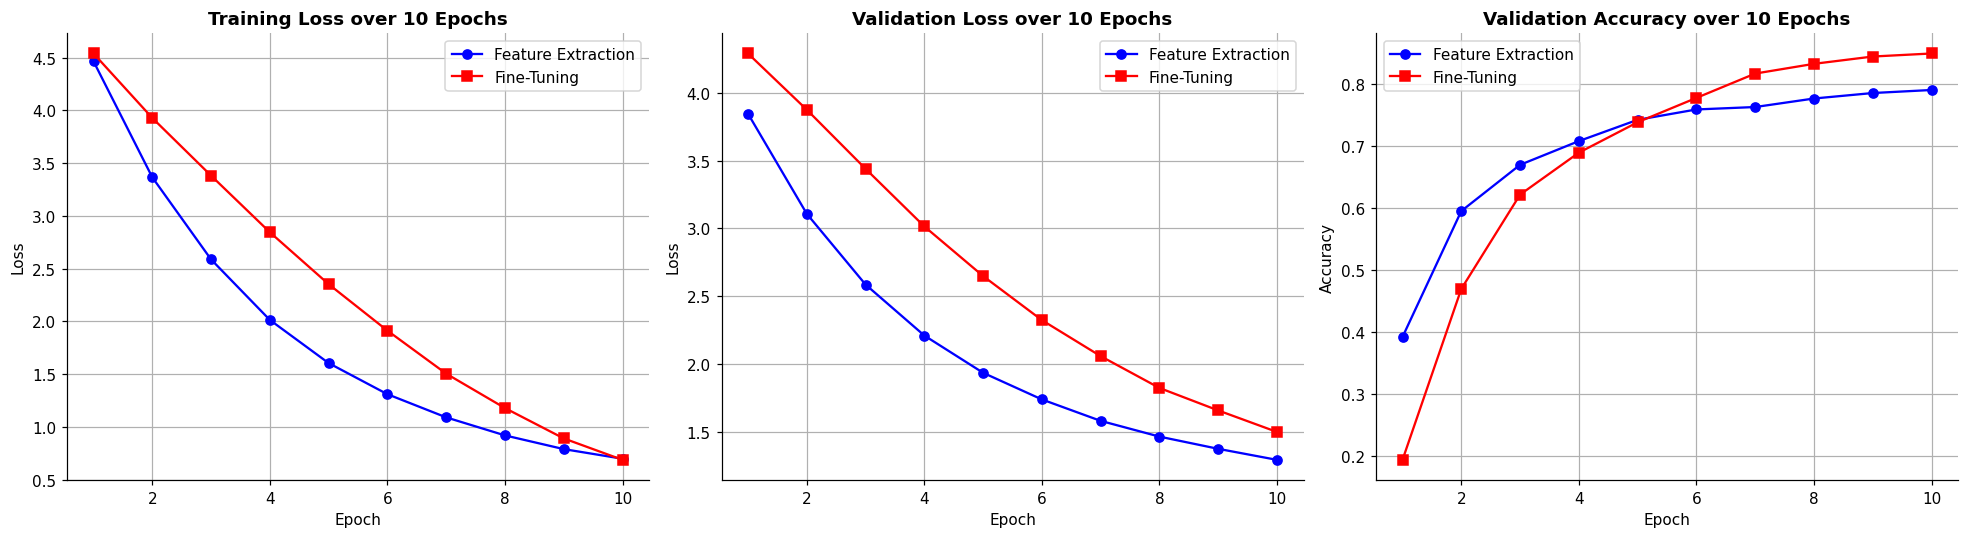

In [11]:
epochs = range(1, 11)

plt.figure(figsize=(18, 5))

# Plot Training Loss
plt.subplot(1, 3, 1)
plt.plot(epochs, history_fe['train_loss'], 'b-o', label='Feature Extraction')
plt.plot(epochs, history_ft['train_loss'], 'r-s', label='Fine-Tuning')
plt.title('Training Loss over 10 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# Plot Validation Loss
plt.subplot(1, 3, 2)
plt.plot(epochs, history_fe['val_loss'], 'b-o', label='Feature Extraction')
plt.plot(epochs, history_ft['val_loss'], 'r-s', label='Fine-Tuning')
plt.title('Validation Loss over 10 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# Plot Validation Accuracy
plt.subplot(1, 3, 3)
plt.plot(epochs, history_fe['val_acc'], 'b-o', label='Feature Extraction')
plt.plot(epochs, history_ft['val_acc'], 'r-s', label='Fine-Tuning')
plt.title('Validation Accuracy over 10 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## Validation confusion matrix and class metrics

Evaluating the best-performing model on the validation set and plotting its confusion matrix.

Best Performing Strategy: Fine-Tuning (Val Acc: 0.8490)


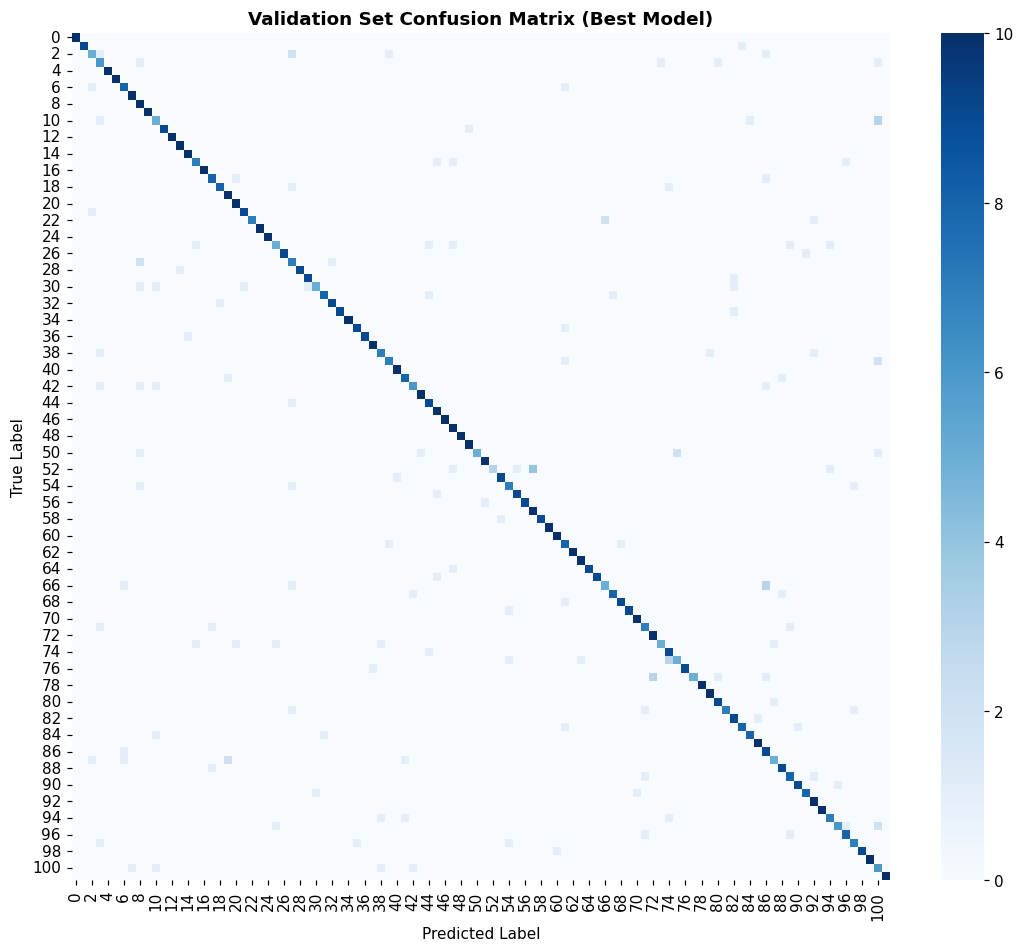

Classification Report Summary:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        10
           1     1.0000    0.9000    0.9474        10
           2     0.6250    0.5000    0.5556        10
           3     0.5000    0.6000    0.5455        10
           4     1.0000    1.0000    1.0000        10
           5     1.0000    1.0000    1.0000        10
           6     0.7273    0.8000    0.7619        10
           7     0.9091    1.0000    0.9524        10
           8     0.5882    1.0000    0.7407        10
           9     1.0000    1.0000    1.0000        10
          10     0.5556    0.5000    0.5263        10
          11     1.0000    0.9000    0.9474        10
          12     1.0000    1.0000    1.0000        10
          13     0.9091    1.0000    0.9524        10
          14     0.9091    1.0000    0.9524        10
          15     0.7778    0.7000    0.7368        10
          16     1.0000    1.0000    1.0000       

In [12]:
# Identify best performing model
best_fe_acc = max(history_fe['val_acc'])
best_ft_acc = max(history_ft['val_acc'])

if best_ft_acc >= best_fe_acc:
    print(f"Best Performing Strategy: Fine-Tuning (Val Acc: {best_ft_acc:.4f})")
    best_model = model_fine_tune
else:
    print(f"Best Performing Strategy: Feature Extraction (Val Acc: {best_fe_acc:.4f})")
    best_model = model_feature_extract

best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = best_model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Generate Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap='Blues', cbar=True)
plt.title('Validation Set Confusion Matrix (Best Model)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Print detailed Classification Report (Top classes excerpt)
print("Classification Report Summary:")
print(classification_report(all_labels, all_preds, zero_division=0, digits=4))

## What I learned

I explored multi-scale Inception blocks, pretrained feature reuse, replacing main and auxiliary classifiers, freezing parameters, smaller learning rates for fine-tuning, and selecting checkpoints with validation data.

The repeated experiment resets seeds before each strategy and freezes BatchNorm running statistics during feature extraction. Plotted training loss and validation loss both use the main classifier; the auxiliary-weighted training objective is recorded separately. The results use the official validation split and should not be interpreted as independent test performance.

,Strategy,Best validation accuracy,Best epoch,Trainable parameters
0,Feature extraction,0.790196,10,313650
1,Fine-tuning,0.849020,10,10243538


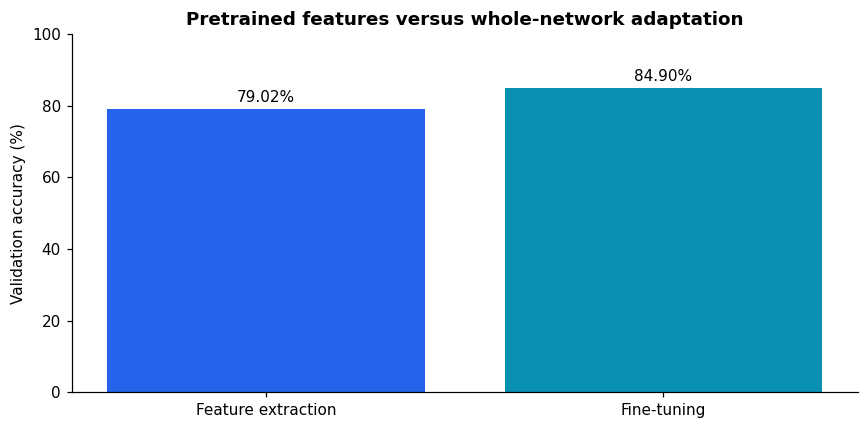

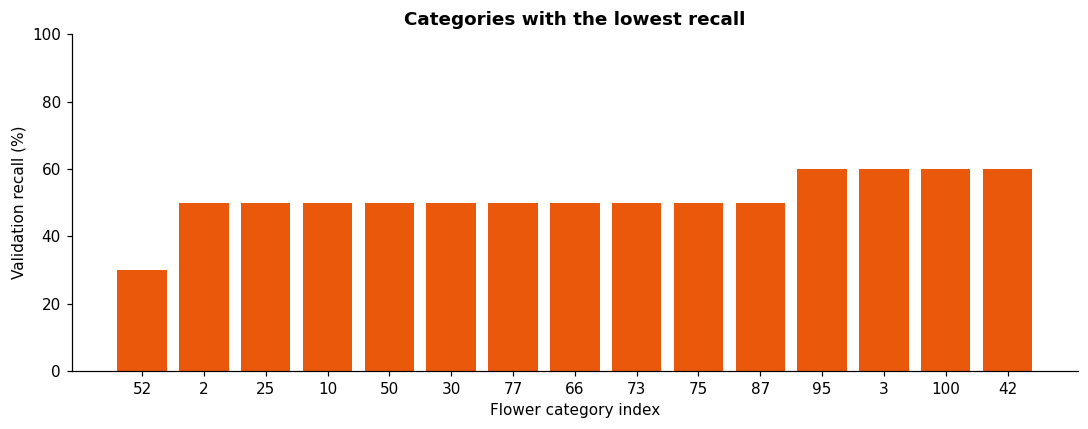

In [13]:
import pandas as pd
comparison = pd.DataFrame([
    {'Strategy': 'Feature extraction', 'Best validation accuracy': max(history_fe['val_acc']),
     'Best epoch': int(np.argmax(history_fe['val_acc'])) + 1,
     'Trainable parameters': sum(p.numel() for p in model_feature_extract.parameters() if p.requires_grad)},
    {'Strategy': 'Fine-tuning', 'Best validation accuracy': max(history_ft['val_acc']),
     'Best epoch': int(np.argmax(history_ft['val_acc'])) + 1,
     'Trainable parameters': sum(p.numel() for p in model_fine_tune.parameters() if p.requires_grad)}
])
display(comparison)
fig,ax=plt.subplots(figsize=(8,4)); bars=ax.bar(comparison['Strategy'],comparison['Best validation accuracy']*100,color=PALETTE[:2])
ax.bar_label(bars,fmt='%.2f%%',padding=3); ax.set(ylabel='Validation accuracy (%)',ylim=(0,100),title='Pretrained features versus whole-network adaptation')
plt.tight_layout(); plt.show()
class_recall=np.divide(np.diag(cm),cm.sum(axis=1),out=np.zeros(len(cm),dtype=float),where=cm.sum(axis=1)!=0)
selected=np.argsort(class_recall)[:15]
fig,ax=plt.subplots(figsize=(10,4));ax.bar([str(i) for i in selected],class_recall[selected]*100,color=PALETTE[2])
ax.set(xlabel='Flower category index',ylabel='Validation recall (%)',ylim=(0,100),title='Categories with the lowest recall')
plt.tight_layout();plt.show()
from pathlib import Path
import json
ARTIFACTS=Path('artifacts/googlenet'); ARTIFACTS.mkdir(parents=True,exist_ok=True)
comparison.to_csv(ARTIFACTS/'strategy_comparison.csv',index=False)
(ARTIFACTS/'results.json').write_text(json.dumps({'feature_extraction':history_fe,'fine_tuning':history_ft},indent=2))
torch.save({'state_dict':best_model.state_dict(),'num_classes':num_classes,'normalization_mean':[.485,.456,.406],
            'normalization_std':[.229,.224,.225]},ARTIFACTS/'best_model.pth')


## Measured findings

Feature extraction reached **79.02%** validation accuracy (epoch 10); fine-tuning reached **84.90%** (epoch 10). These checkpoints were selected on the same validation split, so the comparison is exploratory and is not an independent test estimate.